In [ ]:
!pip install torchmetrics[image]

  Using cached nvidia_cuda_nvrtc_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_runtime_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cuda_cupti_cu12-12.1.105-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cudnn_cu12-8.9.2.26-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cublas_cu12-12.1.3.1-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cufft_cu12-11.0.2.54-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_curand_cu12-10.3.2.106-py3-none-manylinux1_x86_64.whl.metadata (1.5 kB)
  Using cached nvidia_cusolver_cu12-11.4.5.107-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_cusparse_cu12-12.1.0.106-py3-none-manylinux1_x86_64.whl.metadata (1.6 kB)
  Using cached nvidia_nccl_cu12-2.20.5-py3-none-manylinux2014_x86_64.whl.metadata (1.8 kB)
  Using cached nvidia_nvtx_cu12-12.1.105-py3-none-manylinu

In [ ]:
import torch
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.inception import InceptionScore
from google.colab import drive
import os
import zipfile
import matplotlib.pyplot as plt

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def unzip_file(zip_path, extract_to):
    """
    Unzips a file to the specified directory.

    :param zip_path: Path to the zip file.
    :param extract_to: Directory to extract files to.
    """
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
        print(f"Extracted all files to {extract_to}")


zip_path = './drive/MyDrive/nuclear_fuel_bundle_dataset_sorted.zip'
extract_to = './realdata'

# Make sure the extraction directory exists
os.makedirs(extract_to, exist_ok=True)

unzip_file(zip_path, extract_to)

Extracted all files to ./realdata


In [ ]:
!rm -R "./realdata/.ipynb_checkpoints"

rm: cannot remove './realdata/.ipynb_checkpoints': No such file or directory


## **FID and IS**

The Fréchet Inception Distance (FID) and Inception Score (IS) are two widely-used metrics for evaluating the quality of generated images in generative models such as GANs.

**FID** measures the similarity between the distributions of real and generated images by comparing their feature representations from an Inception network, with lower FID values indicating closer similarity and thus higher quality.

**IS**, on the other hand, assesses both the quality and diversity of generated images by computing the entropy of the predicted class probabilities from the Inception network. Higher IS values indicate that the images are both recognizable (high quality) and diverse (spanning multiple classes).

 Together, these metrics provide a comprehensive evaluation of the generative model's performance.

In [ ]:
|def calculate_fid_and_is(real_images_dir, generated_images_dir, batch_size=32, image_size=256):
    """
    Calculate the Fréchet Inception Distance (FID) and Inception Score (IS)
    between real and generated images.

    :param real_images_dir: Directory containing the real images.
    :param generated_images_dir: Directory containing the generated images.
    :param batch_size: Batch size for loading images.
    :param image_size: Size to which images should be resized.
    :return: A tuple (FID score, IS score).
    """
    # Transformation to prepare the images
    transform = transforms.Compose([
        transforms.Resize(image_size),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
    ])

    # Load datasets
    real_dataset = ImageFolder(real_images_dir, transform=transform)
    generated_dataset = ImageFolder(generated_images_dir, transform=transform)

    real_loader = DataLoader(real_dataset, batch_size=batch_size, shuffle=False)
    generated_loader = DataLoader(generated_dataset, batch_size=batch_size, shuffle=False)

    # Initialize FID and IS
    fid = FrechetInceptionDistance(feature=2048)
    inception = InceptionScore()

    def preprocess_image_tensor(tensor):
        # Scale images to 0-255 and convert to uint8
        tensor = (tensor * 255).clamp(0, 255).byte()
        return tensor

    # Calculate FID for real images
    for batch in real_loader:
        images, _ = batch
        images = preprocess_image_tensor(images)
        fid.update(images, real=True)

    # Calculate FID and IS for generated images
    for batch in generated_loader:
        images, _ = batch
        images = preprocess_image_tensor(images)
        fid.update(images, real=False)
        inception.update(images)

    fid_value = fid.compute()
    is_value = inception.compute()

    return fid_value, is_value

In [ ]:
real_images_dir = './realdata/'
generated_images_dir = './drive/MyDrive/Stable Duffusion Generated Image/1000 epochs/'
fid_score, is_score = calculate_fid_and_is(real_images_dir, generated_images_dir)
print(f'FID score - 1000 epochs: {fid_score}')
print(f'Inception Score - 1000 epochs: {is_score}')

FID score - 1000 epochs: 195.05882263183594
Inception Score - 1000 epochs: (tensor(3.5480), tensor(0.3535))


In [ ]:
real_images_dir = './realdata/'
generated_images_dir = './drive/MyDrive/Stable Duffusion Generated Image/2000 epochs/'
fid_score, is_score = calculate_fid_and_is(real_images_dir, generated_images_dir)
print(f'FID score - 2000 epochs: {fid_score}')
print(f'Inception Score - 2000 epochs: {is_score}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 129MB/s]
/usr/local/lib/python3.10/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028


FID score - 2000 epochs: 196.43182373046875
Inception Score - 2000 epochs: (tensor(4.1500), tensor(0.4551))


In [ ]:
real_images_dir = './realdata/'
generated_images_dir = './drive/MyDrive/Stable Duffusion Generated Image/3000 epochs/'
fid_score, is_score = calculate_fid_and_is(real_images_dir, generated_images_dir)
print(f'FID score - 3000 epochs: {fid_score}')
print(f'Inception Score - 3000 epochs: {is_score}')

FID score - 3000 epochs: 185.0645751953125
Inception Score - 3000 epochs: (tensor(4.1117), tensor(0.5648))


In [ ]:
real_images_dir = './realdata/'
generated_images_dir = './drive/MyDrive/Stable Duffusion Generated Image/5000 epochs/'
fid_score, is_score = calculate_fid_and_is(real_images_dir, generated_images_dir)
print(f'FID score - 5000 epochs: {fid_score}')
print(f'Inception Score - 5000 epochs: {is_score}')

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 190MB/s]
/usr/local/lib/python3.10/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `InceptionScore` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028


FID score - 5000 epochs: 197.84193420410156
Inception Score - 5000 epochs: (tensor(3.9146), tensor(0.4122))


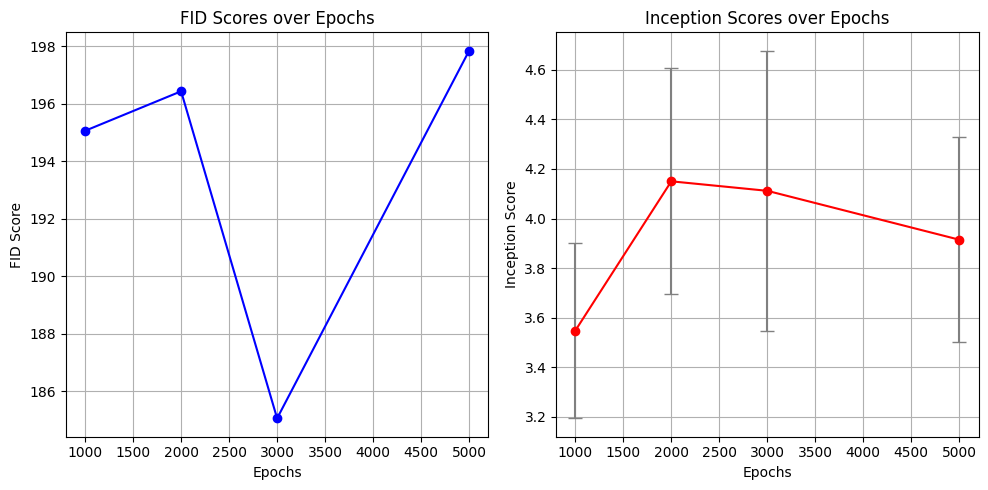

In [ ]:


# Data
epochs = [1000, 2000, 3000, 5000]
fid_scores = [195.05882263183594, 196.43182373046875, 185.0645751953125, 197.84193420410156]
is_means = [3.5480, 4.1500, 4.1117, 3.9146]
is_stds = [0.3535, 0.4551, 0.5648, 0.4122]

# Plot FID scores
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, fid_scores, marker='o', linestyle='-', color='b')
plt.xlabel('Epochs')
plt.ylabel('FID Score')
plt.title('FID Scores over Epochs')
plt.grid(True)

# Plot Inception Scores with error bars
plt.subplot(1, 2, 2)
plt.errorbar(epochs, is_means, yerr=is_stds, fmt='o', linestyle='-', color='r', ecolor='gray', capsize=5)
plt.xlabel('Epochs')
plt.ylabel('Inception Score')
plt.title('Inception Scores over Epochs')
plt.grid(True)

# Show plots
plt.tight_layout()
plt.show()
